# 7.4 Resampling Methods

**Goal:** choose bootstrap, permutation, cross-validation, and Monte Carlo procedures for distinct questions.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Bayesian Statistics](1_Bayesian-Statistics.ipynb)
2. [Parameter Estimation](2_Parameter-Estimation.ipynb)
3. [Multivariate Statistics](3_Multivariate-Statistics.ipynb)
4. [Resampling Methods](4_Resampling-Methods.ipynb)
5. [Experimental Design](5_Experimental-Design.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Bootstrap: Parametric and Non-parametric Bootstrap

A **non-parametric bootstrap** samples observed units with replacement and approximates variability using the empirical distribution. A **parametric bootstrap** simulates from a fitted probability model and refits the statistic. Both inherit assumptions: the first depends on representativeness and suitable resampling units; the second additionally relies on its parametric model.

**Example:** compare bootstrap means by resampling positive observations and by simulating fitted exponential observations. They target related uncertainty under different approximations. BCa, basic, studentized, and percentile intervals have different constructions; no label guarantees reliable rare-tail coverage in tiny samples.

In [2]:
x=rng.exponential(scale=2,size=50);B=3000
nonparam=rng.choice(x,size=(B,len(x)),replace=True).mean(1)
param=rng.exponential(scale=x.mean(),size=(B,len(x))).mean(1)
print("Nonparametric / parametric SE:",nonparam.std(ddof=1),param.std(ddof=1))

Nonparametric / parametric SE: 0.22835293388852307 0.284006814985571


## 2. Permutation Tests

Permutation tests generate a reference by rearranging labels under an appropriate **exchangeability** null or randomized assignment design. They do not generally estimate a statistic's sampling distribution under the alternative, and differ from bootstrap resampling. A randomized experiment can justify reassignment under a sharp null even where an observational label shuffle would be invalid.

For a Monte Carlo two-sided comparison, count permuted statistics at least as extreme as observed and use (b+1)/(B+1), including the observed configuration through the plus-one correction. Pairing and blocks must be preserved. Unequal distribution shapes/variances can invalidate an unstudentized label permutation for a mean-only null.

In [3]:
a=np.array([1.,2.,3.,4.,5.]);b=np.array([3.,4.,5.,6.,7.]);pooled=np.r_[a,b]
observed=a.mean()-b.mean();B=4000
permuted=np.empty(B)
for j in range(B):
    shuffled=rng.permutation(pooled);permuted[j]=shuffled[:len(a)].mean()-shuffled[len(a):].mean()
p=(1+np.sum(np.abs(permuted)>=abs(observed)))/(B+1)
print("Observed difference and permutation p:",observed,p)

Observed difference and permutation p: -2.0 0.13021744563859036


## 3. Cross-validation

Cross-validation estimates predictive performance by repeatedly fitting on training partitions and scoring held-out partitions. Fit imputation, scaling, feature selection, and hyperparameters without using the relevant validation outcomes. Use **nested CV** or a final untouched test set when model selection is involved.

IID K-fold is not universal: group folds keep users together, time-series splits respect chronology, and stratification preserves class coverage where appropriate. Fold scores share overlapping training data and are not independent replicate experiments. Their sample SD divided by √K is not automatically a valid generalization SE.

**Example:** manually cross-validate linear regression, showing that each coefficient fit uses only its fold's training rows. This is evaluation of the specified training procedure, not a formal independent-fold hypothesis test.

In [4]:
X=np.column_stack([np.ones(100),rng.normal(size=100)]);y=X@np.array([1.,2.])+rng.normal(size=100)
folds=np.array_split(rng.permutation(100),5);errors=[]
for validation in folds:
    train=np.setdiff1d(np.arange(100),validation)
    coef=np.linalg.lstsq(X[train],y[train],rcond=None)[0]
    errors.append(np.mean((y[validation]-X[validation]@coef)**2))
print("Fold MSEs:",errors,"average:",np.mean(errors))

Fold MSEs: [np.float64(1.164477737707994), np.float64(1.2936023979104618), np.float64(1.0317752303169467), np.float64(1.1255252686740351), np.float64(1.3301331413580701)] average: 1.1891027551935014


## 4. Monte Carlo Simulation

Monte Carlo approximates expectations by random sampling. For IID draws with finite variance, the mean's MC SE is s/√B, typically converging at order B⁻¹/². It is computational integration error, distinct from data sampling error and model uncertainty. Dependent MCMC draws need effective sample size rather than nominal B.

**Worked example:** estimate $\int_0^1x²dx=1/3$ by sampling U∼Uniform(0,1) and averaging U². A fixed random seed supports reproducibility, but different generators or library versions can produce different streams. Exact identities, not arbitrary random output thresholds, are used to verify formulas.

Integral estimate: 0.3334987549302961 MC SE: 0.0017303424660650123 exact: 0.3333333333333333


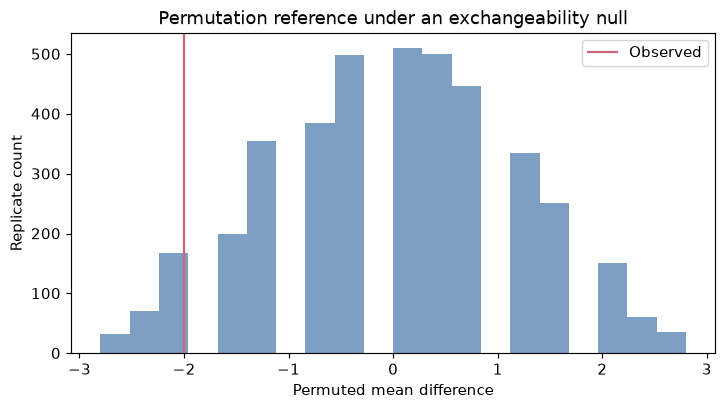

In [5]:
u=rng.uniform(size=30000);h=u*u
print("Integral estimate:",h.mean(),"MC SE:",h.std(ddof=1)/np.sqrt(len(h)),"exact:",1/3)
fig,ax=plt.subplots();ax.hist(permuted,bins=20,color="#4477AA",alpha=.7)
ax.axvline(observed,color="#CC6677",label="Observed")
ax.set(title="Permutation reference under an exchangeability null",xlabel="Permuted mean difference",ylabel="Replicate count");ax.legend()
fig.tight_layout();plt.show()

## AI/ML application and interpretation

Use bootstrap for sampling variability, permutation for a null/design reference, CV for predictive evaluation, and Monte Carlo for integration or model simulation. Their random repetitions serve different purposes. Document the unit, what is refit, and which uncertainty each procedure includes.

## Practice

1. How does parametric bootstrap differ from resampling observed rows?
2. Can labels from repeated measurements be shuffled arbitrarily?
3. Why does tuning on every validation fold and reporting the same best score produce optimism?
4. What does increasing Monte Carlo draws fail to fix?

## Solutions

1. It simulates from a fitted distribution rather than the empirical dataset, adding model assumptions.
2. No. Preserve pairing, blocks, or a valid assignment mechanism.
3. Selection adapts to validation noise; use nested validation or an independent final evaluation.
4. Model misspecification, biased original data, and unaccounted dependence; it primarily reduces integration noise under its sampling assumptions.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](5_Experimental-Design.ipynb).